In [ ]:
##Import libraries: these provide data handling, plotting, model training, evaluation, and saving.

In [1]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

/home/dnw-system-2/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression, SGDClassifier

from sklearn.decomposition import TruncatedSVD

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier

In [ ]:
df =pd.read_csv(r"rows.csv")

/tmp/ipykernel_47655/819953043.py:1: DtypeWarning: Columns (4,5,6,11,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df =pd.read_csv(r"/home/dnw-system-2/Desktop/Gandharvi/rows.csv")


In [4]:
TARGET_COLUMN = "Product"
TEXT_COLUMN = "Consumer complaint narrative"
RANDOM_STATE = 42


In [5]:
df.shape

(1282355, 18)

In [6]:
df.columns

Index(['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue',
       'Consumer complaint narrative', 'Company public response', 'Company',
       'State', 'ZIP code', 'Tags', 'Consumer consent provided?',
       'Submitted via', 'Date sent to company', 'Company response to consumer',
       'Timely response?', 'Consumer disputed?', 'Complaint ID'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1282355 entries, 0 to 1282354
Data columns (total 18 columns):
 #   Column                        Non-Null Count    Dtype 
---  ------                        --------------    ----- 
 0   Date received                 1282355 non-null  object
 1   Product                       1282355 non-null  object
 2   Sub-product                   1047189 non-null  object
 3   Issue                         1282355 non-null  object
 4   Sub-issue                     751169 non-null   object
 5   Consumer complaint narrative  383564 non-null   object
 6   Company public response       449082 non-null   object
 7   Company                       1282355 non-null  object
 8   State                         1262955 non-null  object
 9   ZIP code                      1167057 non-null  object
 10  Tags                          175643 non-null   object
 11  Consumer consent provided?    690654 non-null   object
 12  Submitted via                 1282355 non-

In [8]:
df.isnull().sum()

Date received                         0
Product                               0
Sub-product                      235166
Issue                                 0
Sub-issue                        531186
Consumer complaint narrative     898791
Company public response          833273
Company                               0
State                             19400
ZIP code                         115298
Tags                            1106712
Consumer consent provided?       591701
Submitted via                         0
Date sent to company                  0
Company response to consumer          7
Timely response?                      0
Consumer disputed?               513854
Complaint ID                          0
dtype: int64

In [ ]:
# Clean data: remove unusable rows and duplicates so the models learn from valid examples.
df = df[[TEXT_COLUMN, TARGET_COLUMN]].copy()

# Remove rows where target is missing
df = df.dropna(subset=[TARGET_COLUMN])

# Replace missing text with empty string
df[TEXT_COLUMN] = df[TEXT_COLUMN].fillna("")

# Convert text to string
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str)

# Remove empty complaints
df = df[df[TEXT_COLUMN].str.strip() != ""]

# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)


Shape after cleaning: (367123, 2)


Product
Debt collection                                                                 84317
Credit reporting, credit repair services, or other personal consumer reports    80466
Mortgage                                                                        52945
Credit reporting                                                                29827
Student loan                                                                    21781
Credit card or prepaid card                                                     21292
Credit card                                                                     18757
Bank account or service                                                         14856
Checking or savings account                                                     12858
Consumer Loan                                                                    9443
Vehicle loan or lease                                                            5720
Money transfer, virtual currency, or money ser

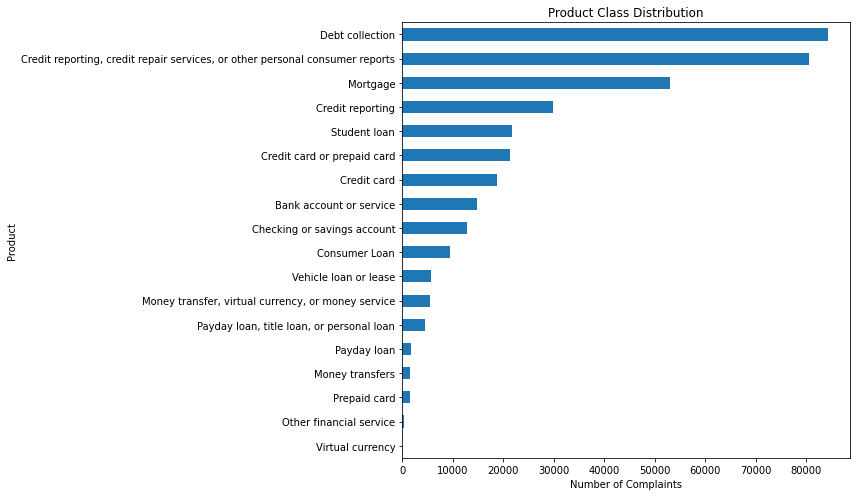

In [ ]:
# Inspect class balance: this reveals whether some product categories are much rarer than others.
class_counts = df[TARGET_COLUMN].value_counts()

print(class_counts)

print("\nClass percentages:")
print(
    (class_counts / len(df) * 100).round(2)
)

# Plot class distribution
plt.figure(figsize=(12, 7))

class_counts.sort_values().plot(kind="barh")

plt.title("Product Class Distribution")
plt.xlabel("Number of Complaints")
plt.ylabel("Product")

plt.tight_layout()
plt.show()


In [ ]:
# Separate input and target, then split: stratification keeps class proportions similar in both sets.

In [11]:
X = df[TEXT_COLUMN]
y = df[TARGET_COLUMN]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples :", len(X_test_text))

Training samples: 293698
Testing samples : 73425


In [ ]:
# Convert text into TF-IDF features: machine-learning models need numeric features, not raw sentences.
# Fit only on training text to prevent information from the test set leaking into training.

tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# IMPORTANT:
# fit_transform only on training data
X_train_tfidf = tfidf.fit_transform(X_train_text)

# Only transform test data
X_test_tfidf = tfidf.transform(X_test_text)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape :", X_test_tfidf.shape)

Training TF-IDF shape: (293698, 30000)
Testing TF-IDF shape : (73425, 30000)


In [ ]:
# Train Logistic Regression:
lr = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr.fit(X_train_tfidf, y_train)

y_pred_lr = lr.predict(X_test_tfidf)

print(
    classification_report(
        y_test,
        y_pred_lr,
        zero_division=0
    )
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    average="macro",
    zero_division=0
)

print("Logistic Regression Macro F1:", round(lr_f1, 4))


                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.63      0.67      0.65      2971
                                                 Checking or savings account       0.68      0.63      0.66      2572
                                                               Consumer Loan       0.58      0.45      0.50      1889
                                                                 Credit card       0.65      0.62      0.64      3751
                                                 Credit card or prepaid card       0.65      0.66      0.66      4258
                                                            Credit reporting       0.71      0.55      0.62      5966
Credit reporting, credit repair services, or other personal consumer reports       0.75      0.81      0.78     16093
                                                       

In [ ]:
# Train SGD Classifier
sgd = SGDClassifier(
    loss="log_loss",
    max_iter=1000,
    random_state=RANDOM_STATE
)

sgd.fit(X_train_tfidf, y_train)

y_pred_sgd = sgd.predict(X_test_tfidf)

print(
    classification_report(
        y_test,
        y_pred_sgd,
        zero_division=0
    )
)

sgd_f1 = f1_score(
    y_test,
    y_pred_sgd,
    average="macro",
    zero_division=0
)

print("SGD Macro F1:", round(sgd_f1, 4))

                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.57      0.60      0.58      2971
                                                 Checking or savings account       0.69      0.37      0.48      2572
                                                               Consumer Loan       0.54      0.11      0.19      1889
                                                                 Credit card       0.65      0.41      0.50      3751
                                                 Credit card or prepaid card       0.57      0.54      0.55      4258
                                                            Credit reporting       0.81      0.10      0.17      5966
Credit reporting, credit repair services, or other personal consumer reports       0.60      0.84      0.70     16093
                                                       

In [ ]:
# Train SGD Classifier with class balancing
sgd_balanced = SGDClassifier(
    loss="log_loss",
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

sgd_balanced.fit(
    X_train_tfidf,
    y_train
)

y_pred_sgd_balanced = sgd_balanced.predict(
    X_test_tfidf
)

print(
    classification_report(
        y_test,
        y_pred_sgd_balanced,
        zero_division=0
    )
)

sgd_balanced_f1 = f1_score(
    y_test,
    y_pred_sgd_balanced,
    average="macro",
    zero_division=0
)

print(
    "Balanced SGD Macro F1:",
    round(sgd_balanced_f1, 4)
)

                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.55      0.62      0.59      2971
                                                 Checking or savings account       0.61      0.56      0.58      2572
                                                               Consumer Loan       0.43      0.35      0.38      1889
                                                                 Credit card       0.53      0.59      0.56      3751
                                                 Credit card or prepaid card       0.61      0.51      0.56      4258
                                                            Credit reporting       0.59      0.46      0.52      5966
Credit reporting, credit repair services, or other personal consumer reports       0.72      0.67      0.70     16093
                                                       

In [ ]:
# Dimensionality reduction with Truncated SVD: this reduces the number of features while preserving most of the information.
svd = TruncatedSVD(
    n_components=300,
    random_state=RANDOM_STATE
)

X_train_svd = svd.fit_transform(
    X_train_tfidf
)

X_test_svd = svd.transform(
    X_test_tfidf
)

print("Original TF-IDF features:", X_train_tfidf.shape[1])

print("Features after SVD:", X_train_svd.shape[1])

print(
    "Explained variance:",
    round(
        svd.explained_variance_ratio_.sum(),
        4
    )
)

Original TF-IDF features: 30000
Features after SVD: 300
Explained variance: 0.1922


In [ ]:
# Train K-Nearest Neighbors (KNN) Classifier
knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=-1
)

knn.fit(
    X_train_svd,
    y_train
)

y_pred_knn = knn.predict(
    X_test_svd
)

print(
    classification_report(
        y_test,
        y_pred_knn,
        zero_division=0
    )
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="macro",
    zero_division=0
)

print("KNN Macro F1:", round(knn_f1, 4))


                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.36      0.55      0.44      2971
                                                 Checking or savings account       0.40      0.46      0.43      2572
                                                               Consumer Loan       0.28      0.28      0.28      1889
                                                                 Credit card       0.43      0.47      0.45      3751
                                                 Credit card or prepaid card       0.47      0.43      0.45      4258
                                                            Credit reporting       0.53      0.47      0.50      5966
Credit reporting, credit repair services, or other personal consumer reports       0.72      0.69      0.70     16093
                                                       

In [ ]:
# XGBoost needs numerical class labels.
classes = sorted(y_train.unique())

class_to_number = {
    label: number
    for number, label in enumerate(classes)
}

number_to_class = {
    number: label
    for label, number in class_to_number.items()
}

y_train_xgb = y_train.map(class_to_number)


# Train XGBoost Classifier
xgb = XGBClassifier(
    n_estimators=150,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=len(classes),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb.fit(
    X_train_svd,
    y_train_xgb
)

y_pred_xgb_number = xgb.predict(
    X_test_svd
).astype(int)

y_pred_xgb = np.array(
    [
        number_to_class[number]
        for number in y_pred_xgb_number
    ]
)

print(
    classification_report(
        y_test,
        y_pred_xgb,
        zero_division=0
    )
)

xgb_f1 = f1_score(
    y_test,
    y_pred_xgb,
    average="macro",
    zero_division=0
)

print("XGBoost Macro F1:", round(xgb_f1, 4))


                                                                              precision    recall  f1-score   support

                                                     Bank account or service       0.55      0.60      0.57      2971
                                                 Checking or savings account       0.58      0.51      0.55      2572
                                                               Consumer Loan       0.47      0.31      0.37      1889
                                                                 Credit card       0.54      0.51      0.53      3751
                                                 Credit card or prepaid card       0.57      0.54      0.55      4258
                                                            Credit reporting       0.66      0.34      0.45      5966
Credit reporting, credit repair services, or other personal consumer reports       0.66      0.80      0.72     16093
                                                       

In [ ]:
# Compare models: this shows which model performed best on the test set.
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SGD",
        "Balanced SGD",
        "KNN",
        "XGBoost"
    ],
    "Macro F1": [
        lr_f1,
        sgd_f1,
        sgd_balanced_f1,
        knn_f1,
        xgb_f1
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_sgd),
        accuracy_score(y_test, y_pred_sgd_balanced),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_xgb)
    ]
})

results = results.sort_values(
    "Macro F1",
    ascending=False
)

print(results.to_string(index=False))


              Model  Macro F1  Accuracy
Logistic Regression  0.563906  0.767749
       Balanced SGD  0.521980  0.701832
            XGBoost  0.475029  0.705659
                KNN  0.440550  0.647436
                SGD  0.339823  0.675710


In [20]:
print("\n========== BEST MODEL ==========")

best_model_name = results.iloc[0]["Model"]

print("Best model based on Macro F1:", best_model_name)



========== BEST MODEL ==========
Best model based on Macro F1: Logistic Regression


In [ ]:
# Review mistakes: seeing incorrect predictions helps identify categories the model confuses.
predictions = {
    "Logistic Regression": y_pred_lr,
    "SGD": y_pred_sgd,
    "Balanced SGD": y_pred_sgd_balanced,
    "KNN": y_pred_knn,
    "XGBoost": y_pred_xgb
}

best_predictions = predictions[best_model_name]


In [22]:


error_analysis = pd.DataFrame({
    "Text": X_test_text.reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(best_predictions)
})

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Total test samples:", len(error_analysis))
print("Incorrect predictions:", len(errors))

print("\nSample errors:")

print(
    errors.head(10).to_string(index=False)
)

# Save error analysis
error_analysis.to_csv(
    "error_analysis.csv",
    index=False
)

print("\nSaved: error_analysis.csv")

Total test samples: 73425
Incorrect predictions: 17053

Sample errors:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                 


Saved: error_analysis.csv


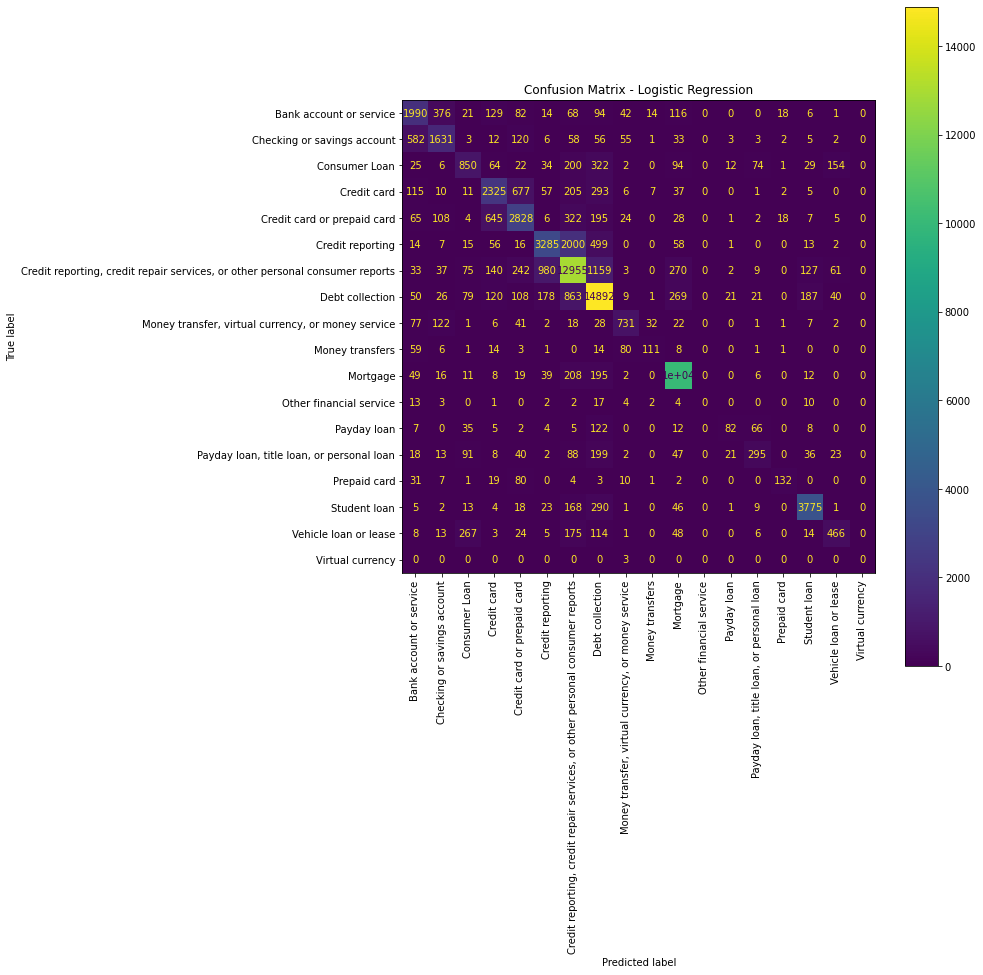

In [ ]:
# Plot the confusion matrix: it shows which product labels are often mistaken for other labels.
fig, ax = plt.subplots(
    figsize=(14, 14)
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    ax=ax,
    xticks_rotation="vertical"
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.tight_layout()
plt.show()

In [24]:
joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

# Save models
joblib.dump(
    lr,
    "logistic_regression.pkl"
)

joblib.dump(
    sgd,
    "sgd.pkl"
)

joblib.dump(
    sgd_balanced,
    "sgd_balanced.pkl"
)

joblib.dump(
    knn,
    "knn.pkl"
)

joblib.dump(
    svd,
    "svd.pkl"
)

joblib.dump(
    xgb,
    "xgboost.pkl"
)

print("Models saved successfully.")

Models saved successfully.


In [25]:
print("Best model:", best_model_name)
print("Best Macro F1:", round(results.iloc[0]["Macro F1"], 4))

Best model: Logistic Regression
Best Macro F1: 0.5639
